In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

plt.style.use('seaborn-v0_8-darkgrid')

BASE_DIR = Path("..")
PROCESSED_DIR = BASE_DIR / "data" / "processed"
TICKERS = ["SPY", "QQQ", "IWM", "TLT", "GLD"]

data = {ticker: pd.read_csv(PROCESSED_DIR / f"{ticker}_processed.csv", index_col='Date', parse_dates=True) for ticker in TICKERS}

# Create a combined returns dataframe
returns = pd.DataFrame({ticker: data[ticker]['Daily_Return'] for ticker in TICKERS})

In [2]:
# We will look at 63-day (1 quarter) rolling correlations
window = 63

# 1. SPY vs TLT (Equities vs Bonds - the classic 60/40 portfolio)
spy_tlt_corr = returns['SPY'].rolling(window=window).corr(returns['TLT'])

# 2. SPY vs GLD (Equities vs Gold - the "safe haven")
spy_gld_corr = returns['SPY'].rolling(window=window).corr(returns['GLD'])

# 3. QQQ vs IWM (Large Cap Tech vs Small Cap)
qqq_iwm_corr = returns['QQQ'].rolling(window=window).corr(returns['IWM'])

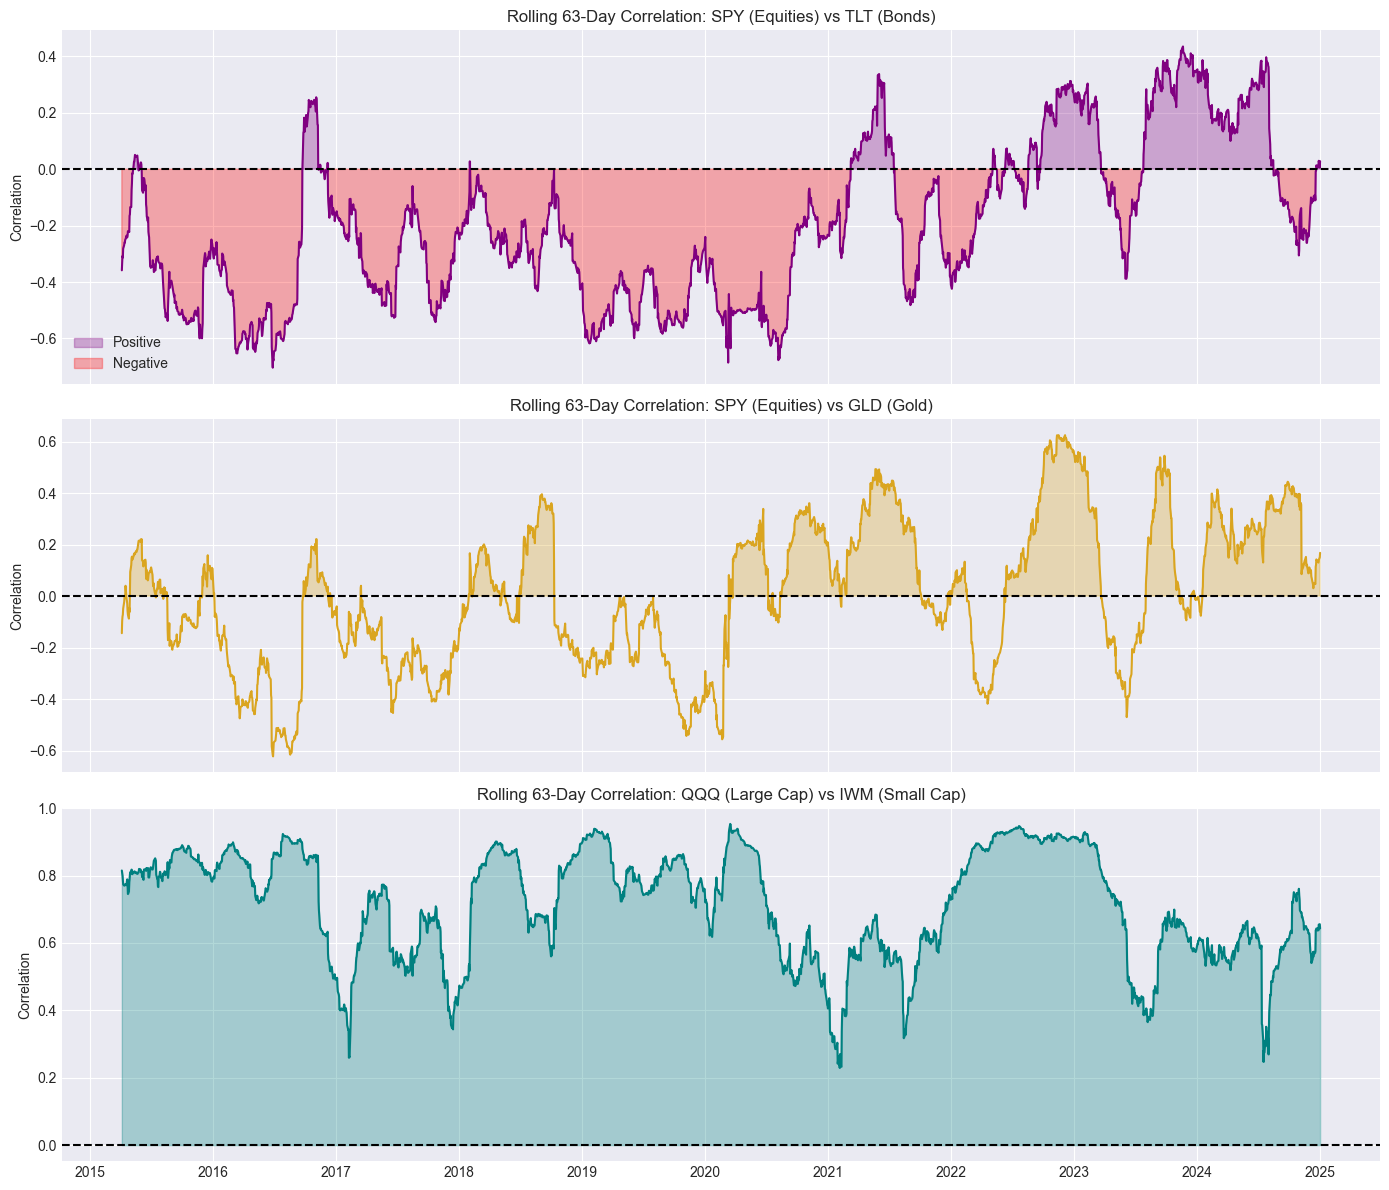

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

# SPY vs TLT
axes[0].plot(spy_tlt_corr, color='purple', linewidth=1.5)
axes[0].axhline(0, color='black', linestyle='--')
axes[0].set_title("Rolling 63-Day Correlation: SPY (Equities) vs TLT (Bonds)", fontsize=12)
axes[0].set_ylabel("Correlation")
axes[0].fill_between(spy_tlt_corr.index, spy_tlt_corr, 0, where=(spy_tlt_corr > 0), color='purple', alpha=0.3, label='Positive')
axes[0].fill_between(spy_tlt_corr.index, spy_tlt_corr, 0, where=(spy_tlt_corr < 0), color='red', alpha=0.3, label='Negative')
axes[0].legend(loc='lower left')

# SPY vs GLD
axes[1].plot(spy_gld_corr, color='goldenrod', linewidth=1.5)
axes[1].axhline(0, color='black', linestyle='--')
axes[1].set_title("Rolling 63-Day Correlation: SPY (Equities) vs GLD (Gold)", fontsize=12)
axes[1].set_ylabel("Correlation")
axes[1].fill_between(spy_gld_corr.index, spy_gld_corr, 0, where=(spy_gld_corr > 0), color='goldenrod', alpha=0.3)

# QQQ vs IWM
axes[2].plot(qqq_iwm_corr, color='teal', linewidth=1.5)
axes[2].axhline(0, color='black', linestyle='--')
axes[2].set_title("Rolling 63-Day Correlation: QQQ (Large Cap) vs IWM (Small Cap)", fontsize=12)
axes[2].set_ylabel("Correlation")
axes[2].fill_between(qqq_iwm_corr.index, qqq_iwm_corr, 0, where=(qqq_iwm_corr > 0), color='teal', alpha=0.3)

plt.tight_layout()
plt.show()

In [4]:
print("=== CORRELATION BREAKDOWN ANALYSIS ===")
print("Average Correlation (2015-2021):")
print(f"SPY-TLT: {spy_tlt_corr.loc[:'2021-12-31'].mean():.3f}")
print(f"SPY-GLD: {spy_gld_corr.loc[:'2021-12-31'].mean():.3f}")
print(f"QQQ-IWM: {qqq_iwm_corr.loc[:'2021-12-31'].mean():.3f}\n")

print("Average Correlation (2022-2024):")
print(f"SPY-TLT: {spy_tlt_corr.loc['2022-01-01':].mean():.3f}")
print(f"SPY-GLD: {spy_gld_corr.loc['2022-01-01':].mean():.3f}")
print(f"QQQ-IWM: {qqq_iwm_corr.loc['2022-01-01':].mean():.3f}")

=== CORRELATION BREAKDOWN ANALYSIS ===
Average Correlation (2015-2021):
SPY-TLT: -0.320
SPY-GLD: -0.064
QQQ-IWM: 0.715

Average Correlation (2022-2024):
SPY-TLT: 0.071
SPY-GLD: 0.158
QQQ-IWM: 0.712


## Experiment D Conclusion: Cross-Asset Relationships

**1. Correlations are not stable over time.**
By analyzing rolling 63-day correlations, we found that relationships between asset classes experience significant regime shifts.

**2. The 2022 "60/40" breakdown.**
The correlation between SPY (Equities) and TLT (Bonds) flipped from strongly negative (-0.32 average from 2015-2021) to positive (+0.07 average from 2022-2024). This means that during the 2022 inflation shock, bonds failed to act as a safe haven and instead fell alongside equities. Similarly, SPY and GLD flipped from negative (-0.064) to positive (+0.158).

**3. Equity correlations remain stable.**
The correlation between QQQ and IWM (Large Cap vs Small Cap) remained highly positive and stable throughout the entire period (0.715 vs 0.712), confirming that within the same asset class, relationships are much more persistent.

**Conclusion:**
Cross-asset hedges based on historical correlations are fragile. Any strategy relying on bonds as a hedge against equities must have a regime-detection mechanism to avoid the 2022-style breakdown.